# Singular Value Decomposition (SVD)

The standard Singular Value Decomposition of a matrix $A$ is given by:

$$A = U \Sigma V^T$$
---

## Component Breakdown

* **$A \in \mathbb{R}^{m \times n}$**: The original input matrix.
* **$U \in \mathbb{R}^{m \times m}$**: An orthogonal (unitary) matrix whose columns are the **left-singular vectors** of $A$ (eigenvectors of $AA^T$).
* **$\Sigma \in \mathbb{R}^{m \times n}$**: A rectangular diagonal matrix containing non-negative **singular values** $\sigma_i$ along the diagonal, arranged in descending order ($\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r \ge 0$).
* **$V^T \in \mathbb{R}^{n \times n}$** (or $V^*$): The transpose (or conjugate transpose) of an orthogonal matrix $V$ whose columns are the **right-singular vectors** of $A$ (eigenvectors of $A^T A$).

---

## Summation Form (Rank-$r$ Expansion)

SVD can also be written as a sum of rank-1 outer products:

$$A = \sum_{i=1}^{r} \sigma_i u_i v_i^T$$

Where:
* $r = \text{rank}(A)$
* $u_i$ is the $i$-th column vector of $U$
* $v_i$ is the $i$-th column vector of $V$
* $\sigma_i$ is the $i$-th singular value

In [ ]:
import numpy as np
import scipy as sci

In [ ]:
A=np.random.randint(0,100,size=(10,5))

In [ ]:
U,S,V=sci.linalg.svd(A,full_matrices=False)

In [ ]:
display(U)
display(S)
display(V)

array([[-0.31211209,  0.29590593,  0.09687617,  0.08868916, -0.48342662],
       [-0.39600299, -0.38190905,  0.28871296,  0.23290645,  0.29391748],
       [-0.29034566, -0.49773137, -0.30034048, -0.34237094, -0.60647846],
       [-0.33380425,  0.08633691, -0.4370673 ,  0.34595261,  0.07062007],
       [-0.24525207,  0.44546952,  0.10791091, -0.14935701, -0.10378488],
       [-0.36467442,  0.45596388, -0.1154678 , -0.05084515,  0.02098258],
       [-0.23428088,  0.03854724, -0.54188178, -0.01013282,  0.40183146],
       [-0.26775899, -0.30766598, -0.10378625, -0.01272756,  0.14784319],
       [-0.32816785, -0.09391446,  0.42344361,  0.48199948, -0.1183958 ],
       [-0.35018457,  0.00917885,  0.34254649, -0.66596309,  0.31393095]])

array([327.38697208, 128.71539367, 100.07297944,  46.35882178,
        35.85214608])

array([[-0.56388472, -0.3725878 , -0.4782848 , -0.45393336, -0.32924233],
       [-0.39109972, -0.44797422,  0.5441292 , -0.13734526,  0.57569072],
       [-0.70096335,  0.38298841, -0.04819915,  0.59961518,  0.01042787],
       [ 0.19357037, -0.63160888, -0.42366972,  0.59249364,  0.18181305],
       [-0.01599776, -0.33895062,  0.54161598,  0.25395612, -0.72595796]])

In [ ]:
print(U.shape, S.shape, V.shape)

(10, 5) (5,) (5, 5)


In [ ]:
np.allclose(U.T@U,np.identity(5))

True

In [ ]:
 np.allclose(U @ np.diag(S) @ V, A)


True

In [ ]:
np.linalg.matrix_rank(A) == len(S)

np.True_

In [ ]:
import numpy as np
import cv2

### Image Compression For Gray Scale Images

In [ ]:
def compress_image(image_path,k):
  img=cv2.imread(image_path,cv2.IMREAD_GRAYSCALE)
  img_mat=img.astype(np.float64)
  U,S,Vt=np.linalg.svd(img_mat,full_matrices=False)
  #truncating to k values
  U_k=U[:,:k]
  S_k=np.diag(S[:k])
  Vt_k=Vt[:k,:]       # Corrected to select all columns for the first k rows
  comp_img=np.dot(U_k,np.dot(S_k,Vt_k))
  comp_img=np.clip(comp_img,0,255).astype(np.uint8)
  return img,comp_img

In [ ]:
original,compressed=compress_image('practiceimg.png',100)

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       ...,
       [134, 150, 117, ..., 190, 190, 184],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)
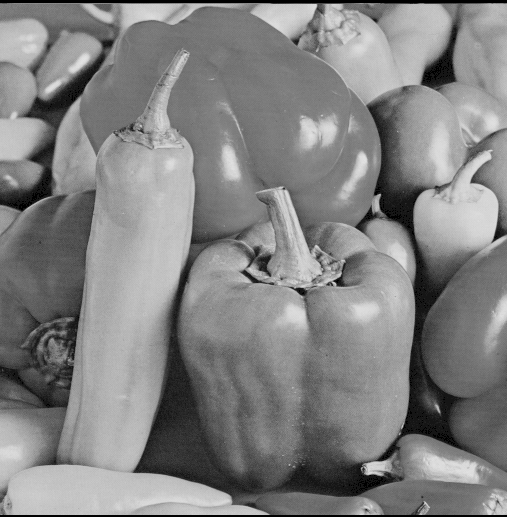

In [ ]:
original

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       ...,
       [131, 128, 120, ..., 188, 182, 182],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)
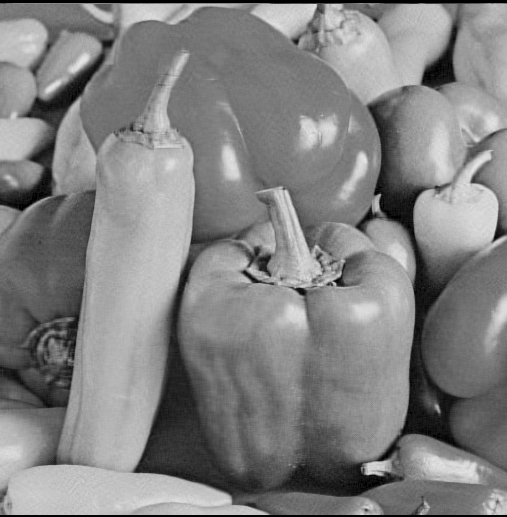

In [ ]:
compressed

In [ ]:
cv2.imwrite('compressed.jpg', compressed)

True

### Image Compression For Colour Images

In [ ]:
def compress_image_col(image_path,k):
  img=cv2.imread(image_path)
  img= cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  compress_channels=[]
  for channel in cv2.split(img):
    channel_mat=channel.astype(np.float64)
    U,S,Vt=np.linalg.svd(channel_mat,full_matrices=False)
    #truncating to k values
    U_k=U[:,:k]
    S_k=np.diag(S[:k])
    Vt_k=Vt[:k,:]
    comp_channel=np.dot(U_k,np.dot(S_k,Vt_k))
    comp_channel=np.clip(comp_channel,0,255).astype(np.uint8)
    compress_channels.append(comp_channel)
  comp_img=cv2.merge(compress_channels)
  return img,comp_img

In [ ]:
orig,comp=compress_image_col('practiceimg.png',100)

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       ...,

       [[136, 143,  57],
        [141, 164,  72],
        [136, 113,  59],
        ...,
        [170, 204, 162],
        [171, 204, 153],
        [166, 199, 150]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]], dtype=uint8)
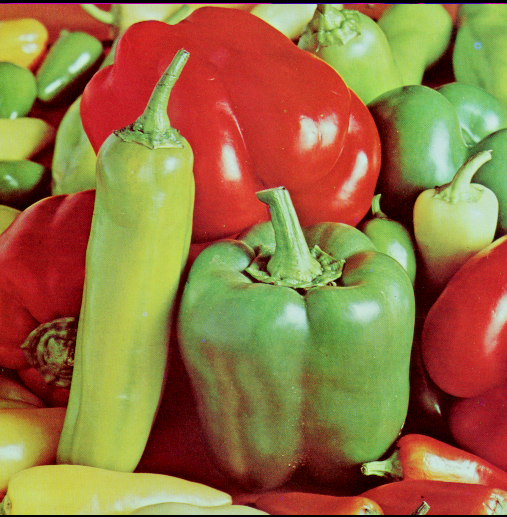

In [ ]:
orig

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       ...,

       [[133, 137,  53],
        [127, 133,  59],
        [127, 120,  52],
        ...,
        [172, 205, 158],
        [167, 195, 150],
        [170, 191, 154]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]], dtype=uint8)
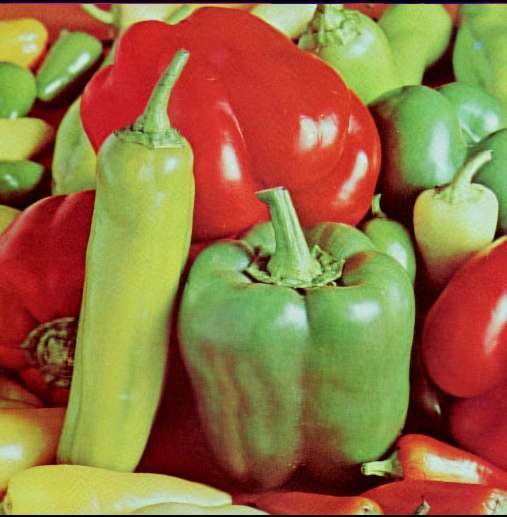

In [ ]:
comp